# Depth pruning: zero-shot loss vs. layers pruned

Part of plan.md step 2.1 -- the first real pruning experiment in this
project. Everything before this notebook (1.3, 2.1's scoring half) only
*scored* which layers matter; this notebook actually removes layers
(`bonsai.pruning.depth.prune_layers`) and measures the resulting
zero-shot loss (`bonsai.importance.depth.mean_loss`) on
`Qwen3-30B-A3B-Base`, at nine layer counts (1, 2, 4, 6, 8, 12, 16, 20, 24
of 48), under four selection strategies:

- **bi\_greedy**: prune the $n$ lowest-Block-Importance layers (the cheap,
  validated proxy from `03_importance_scores.ipynb`).
- **ppl\_greedy**: prune the $n$ lowest-perplexity-delta layers (the
  expensive ground truth from `04_ppl_depth_scoring.ipynb`).
- **contiguous\_bi**: prune the single best (lowest-summed-BI) *contiguous*
  block of $n$ layers -- tests 2408.11796's own claim (citing Gromov et
  al.) that contiguous removal beats scattered removal, on this model
  specifically.
- **random**: prune $n$ random layers, 3 seeds -- the control every
  principled strategy above needs to actually beat, not just correlate
  well with each other.

Each candidate costs exactly one forward pass over 32 fresh calibration
samples (seed=1, disjoint draw from the same pinned calibration shard
used everywhere else) -- cheap, since we already know which layers to
drop; the expensive part (deciding the ranking) already happened in 1.3
and 2.1's scoring half. The actual GPU orchestration lives in a throwaway
script, same convention as every prior collection run; this notebook
loads the saved results and visualizes them.

In [1]:
import torch

RUN_DIR = "../runs/20260919T212614Z-a67cb3-depth-pruning-sweep"
data = torch.load(f"{RUN_DIR}/depth-pruning-sweep.pt", weights_only=False)

results = data["results"]
counts = data["counts"]
baseline_loss = next(r["loss"] for r in results if r["strategy"] == "baseline")

print(
    f"{data['num_layers']} layers, {data['num_samples']} calibration samples, mean length {data['mean_length']:.0f} tokens"
)
print(f"counts swept: {counts}")
print(f"baseline (0 pruned) loss: {baseline_loss:.4f}")
print(f"{len(results)} total candidates evaluated")

48 layers, 32 calibration samples, mean length 176 tokens
counts swept: [1, 2, 4, 6, 8, 12, 16, 20, 24]
baseline (0 pruned) loss: 0.9670
55 total candidates evaluated


## The main result

One line per strategy, random shown as a mean line plus its min-max band
across seeds -- the y-axis is log-scale since a handful of unlucky random
draws blow up by more than an order of magnitude.

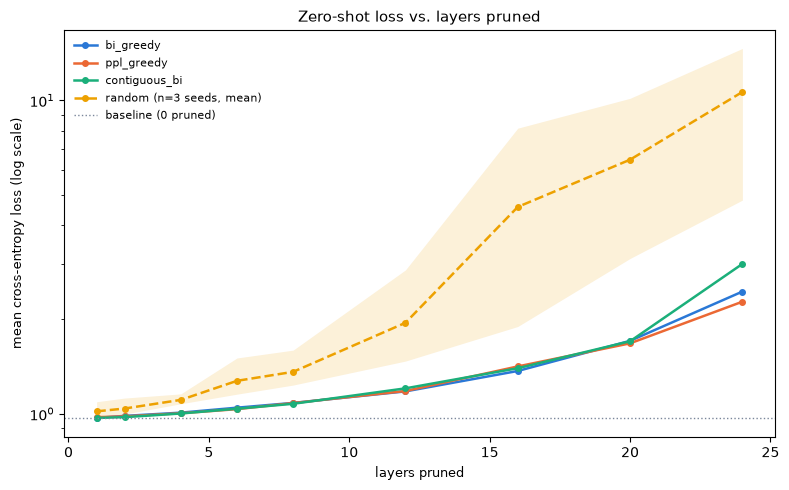

In [2]:
from bonsai.pruning.viz import plot_pruning_sweep

named_losses = {
    strategy: [
        next(r["loss"] for r in results if r["strategy"] == strategy and r["n"] == n)
        for n in counts
    ]
    for strategy in ("bi_greedy", "ppl_greedy", "contiguous_bi")
}
random_losses = [
    [r["loss"] for r in results if r["strategy"] == "random" and r["n"] == n] for n in counts
]

fig = plot_pruning_sweep(counts, named_losses, random_losses, baseline_loss=baseline_loss)
fig.savefig(f"{RUN_DIR}/pruning_sweep.png", dpi=150)
fig.savefig(f"{RUN_DIR}/pruning_sweep.pdf")

## Numbers behind the plot

Loss relative to baseline, as a percentage increase -- easier to compare
across strategies at a glance than raw nats.

In [3]:
import numpy as np

random_mean = np.array(random_losses).mean(axis=1)

header = (
    f"{'n':>3}  {'bi_greedy':>10}  {'ppl_greedy':>11}  {'contiguous_bi':>14}  {'random_mean':>12}"
)
print(header)
print("-" * len(header))
for i, n in enumerate(counts):
    row = [
        named_losses[s][i] / baseline_loss - 1 for s in ("bi_greedy", "ppl_greedy", "contiguous_bi")
    ]
    row.append(random_mean[i] / baseline_loss - 1)
    print(
        f"{n:>3}  "
        + "  ".join(f"{v:>+10.1%}" if j < 3 else f"{v:>+11.1%} " for j, v in enumerate(row))
    )

  n   bi_greedy   ppl_greedy   contiguous_bi   random_mean
----------------------------------------------------------
  1       +0.3%       +0.9%       +0.3%        +5.3% 
  2       +1.8%       +1.4%       +0.9%        +7.5% 
  4       +4.3%       +3.8%       +3.6%       +14.5% 
  6       +8.1%       +7.0%       +7.3%       +31.7% 
  8      +12.0%      +11.9%      +11.3%       +40.7% 
 12      +21.9%      +22.2%      +24.6%      +101.8% 
 16      +41.6%      +46.4%      +44.5%      +372.6% 
 20      +76.7%      +73.5%      +76.2%      +568.8% 
 24     +153.8%     +135.6%     +211.0%     +1000.1% 


## Does contiguous-block removal actually help here?

2408.11796 (citing Gromov et al.) reports contiguous removal beats
scattered removal. On this model, at this scale, the picture is mixed:
`contiguous_bi` is competitive -- even marginally *best* -- at small counts
(it wins outright at $n=2$), but falls behind both greedy strategies as
the count grows, most visibly by $n=24$. A plausible reading: BI's
lowest-scoring layers already cluster in a contiguous run in the middle of
the model (visible in `03_importance_scores.ipynb`'s per-layer summary
chart), so for small $n$ the two approaches pick nearly the same layers
anyway; forcing strict contiguity only starts costing something once $n$
grows past what that natural cluster contains, forcing the contiguous
search into a wider, less-optimal window. This is reported as an honest,
mixed result, not a clean win either way -- consistent with this
project's own convention (plan.md already logs the EvoESAP non-uniform-
allocation negative result the same way) of keeping negative or
complicating findings visible rather than only reporting the clean ones.

## Summary

- **Principled selection clearly beats random**, at every layer count
  tested, often by close to an order of magnitude once more than a
  handful of layers are pruned (e.g. at $n=24$: bi\_greedy/ppl\_greedy
  loss around 2.3-2.5 vs. random seeds ranging 4.8-14.6). This is the
  basic sanity check every pruning criterion has to clear, and both of
  1.3/2.1's scoring methods clear it decisively.
- **BI and PPL-greedy track each other closely** at every count, not just
  in the ranking-correlation sense already established (Pearson
  $r=0.91$) -- acting on BI's cheap ranking produces almost the same
  pruning outcome as acting on PPL's expensive one, reinforcing that BI
  can be trusted as the working criterion for iterating on candidates.
- **Contiguous-block removal is a mixed result** on this model: helpful or
  neutral at small counts, mildly harmful relative to the greedy
  strategies at larger ones (\S above).
- **Loss grows roughly monotonically with layers pruned** under every
  strategy, as expected, but principled selection keeps that growth far
  more contained than chance -- pruning up to half the informative
  capacity (24 of 48 layers, by BI/PPL ranking) still lands at a loss
  increase far smaller than pruning even 8-12 random layers.

**What this means for Phase 2 going forward:** BI-greedy is the working
choice for depth pruning's ranking criterion, confirmed twice now --
once by correlation with PPL (2.1's scoring half), once by actually
acting on it and measuring the outcome (this notebook). The actual target
layer count for a real candidate, and how depth interacts with width/expert
pruning once combined (2.4), are still open.